# NeMo AutoModel LoRA: Voice Memory with NVIDIA NIM and NeMo

The LoRA path is a separate weight-adaptation baseline and is not the original frozen-model Voice Memory method. The included English normalization is not a multilingual tokenizer. Reference text is never included in correction prompts. NeMo Speech audio transcription is an optional 1-best input path; it is not claimed to reconstruct the original Whisper 5-best oracle.


GPU environment: use NVIDIA's `nvcr.io/nvidia/nemo-automodel:26.10.00` container, then install this repo editable. The direct loader/LoRA APIs are source-checked against AutoModel commit `c57935fc64faea913ce9f5e38ea7e57e6416cc93`. If a container's package predates these APIs, install that exact source revision in an isolated environment, record the installed revision, and rerun validation. Never upgrade the user's unrelated environment.

The training loop performs actual gradient updates, saves adapter tensors, clears and reloads them, verifies exact reload equality, and generates before/after held-out outputs. Failure of any step is a failed run, not a passed import check. Start on one H100 for the small teaching models. Record actual peak memory before increasing the sample size.


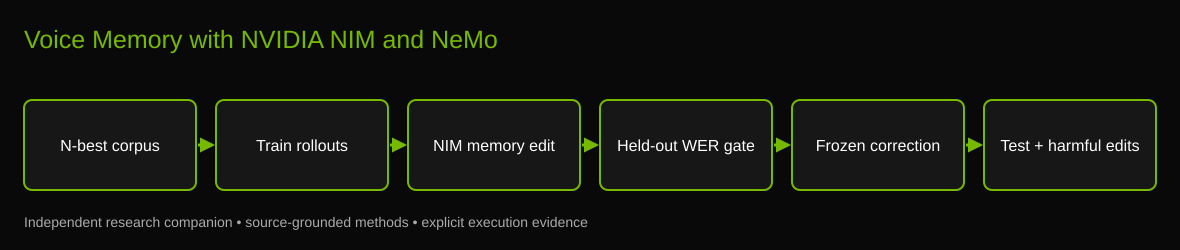

In [1]:
from pathlib import Path
import os, subprocess, sys
REPO = "voice-memory-nvidia"
if not Path("pyproject.toml").exists():
    if not Path(REPO).exists():
        subprocess.run(["git", "clone", "https://github.com/virginiakm1988/" + REPO + ".git", REPO], check=True)
    os.chdir(REPO)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[tutorial]"], check=True)
from IPython.display import display, SVG
display(SVG(filename="assets/overview.svg"))


## GPU preflight
Use a connected Linux GPU runtime with the pinned NVIDIA environment. The next cell checks readiness without silently installing a different torch stack.

In [2]:
import ipywidgets as widgets, importlib.metadata
RUN_TRAINING = widgets.Checkbox(value=False, description="Run real GPU training")
display(RUN_TRAINING)
print("Training is opt-in. Use the documented isolated A100/H100 NVIDIA environment; CPU previews do not train.")


Checkbox(value=False, description='Run real GPU training')

Training is opt-in. Use the documented isolated A100/H100 NVIDIA environment; CPU previews do not train.


## Train and reload
This is an explicit live training cell. For Voice Memory set DATA_DIR to the prepared independent N-best corpus. For SpeechEQ use the bundled ASR warm-up configuration, not benchmark test audio.

In [3]:
if RUN_TRAINING.value:
    CONFIG = "configs/default.json"
    DATA_DIR = None  # Set a corpus folder when required.
    cmd = [sys.executable, "-m", "project_demo", "train", "--mode", "live", "--config", CONFIG, "--steps", "20", "--output-dir", "runs"]
    if DATA_DIR:
        cmd += ["--data-dir", DATA_DIR]
    subprocess.run(cmd, check=True)
else:
    print("Training not launched. Saved real-run evidence is displayed below when available.")


Training not launched. Saved real-run evidence is displayed below when available.


## Before/after evidence
Verify actual_weight_update and adapter_reload_exact. Inspect held-out outputs and report decreases as well as improvements.

In [4]:
import json
for path in sorted(Path("runs").glob("*/heldout-comparison.json"))[-1:]:
    display(json.loads(path.read_text()))


## Saved execution evidence
These files are outputs from separate recorded CLI/SDK runs. Reading them makes no model requests and does not claim the current notebook session performed GPU training.

In [6]:
import json
from pathlib import Path
for folder in sorted(Path("evidence").glob("*")):
    if folder.is_dir() and (folder/"execution.json").exists():
        record=json.loads((folder/"execution.json").read_text(encoding="utf-8"))
        print("Run:",folder.name,"mode:",record["mode"],"status:",record["status"])
        if (folder/"results.json").exists():
            display(json.loads((folder/"results.json").read_text(encoding="utf-8")))

        if (folder/"heldout-task-metrics.json").exists():
            display(json.loads((folder/"heldout-task-metrics.json").read_text(encoding="utf-8")))


Run: 20261116T091303-prepare-60f77848 mode: live status: passed


{'dataset': 'PeacefulData/HyPoradise-v0',
 'revision': '9c896c358dd3bcd7e856af879b31e4353d2a0294',
 'domain': 'atis',
 'original_counts': {'train': 3964, 'test': 809},
 'excluded_training_rows_overlapping_test': 39,
 'counts': {'train': 3, 'selection': 3, 'test': 3},
 'selected_ids': {'train': ['r80011ss', '600014ss', '4l00v1ss'],
  'selection': ['fa0074ss', 'iv0037ss', '8kz074ss'],
  'test': ['i09067ss', 'g0w033ss', 'g0v012ss']},
 'selection_rule': 'seeded shuffle of official train only; official test untouched',
 'data_sha256': '8202a7e2fd75c2b1c2332961dfa3822ae1312d0c221dfc45f1cd93c7e0727928',
 'license': 'MIT dataset card; verify original corpus terms'}

Run: 20261116T091608-train-08b48ab2 mode: live status: blocked
Run: 20261116T091705-evaluate-ef857a00 mode: live status: passed


{'evidence_kind': 'live_nim',
 'static': {'n': 3,
  'wer': 0.08108108108108109,
  'cer': 0.030864197530864196,
  'one_best_wer': 0.08108108108108109,
  'oracle_wer': 0.08108108108108109,
  'recoverable_headroom_fraction': None,
  'harmful_edit_rate_among_changed': 0.0,
  'changed_utterances': 1,
  'harmful_edits': 0},
 'optimized_memory': {'n': 3,
  'wer': 0.08108108108108109,
  'cer': 0.030864197530864196,
  'one_best_wer': 0.08108108108108109,
  'oracle_wer': 0.08108108108108109,
  'recoverable_headroom_fraction': None,
  'harmful_edit_rate_among_changed': 0.0,
  'changed_utterances': 1,
  'harmful_edits': 0},
 'memory': [],
 'optimizer_history': [{'iteration': 0,
   'edit': {'operation': 'add',
    'text': 'please give me the flights from san francisco to washington d c',
    'index': 0},
   'previous_wer': 0.05,
   'candidate_wer': 0.35,
   'accepted': False},
  {'iteration': 1,
   'edit': {'operation': 'add',
    'text': 'please give me the flights from san francisco to washington

Run: 20261116T091834-train-c006fe42 mode: live status: failed
Run: 20261116T092728-train-8d6ecb22 mode: live status: failed
Run: 20261116T093146-train-8de3529a mode: live status: failed
Run: 20261116T093202-transcribe-b99b6f3b mode: live status: passed


{'evidence_kind': 'actual_nemo_speech_audio',
 'model': 'nvidia/parakeet-tdt-0.6b-v3',
 'outputs': [{'audio': 'assets/authored-example.wav',
   'one_best': 'Please let me finish explaining the problem before we decide.'}],
 'scope': 'one-best audio input, not original N-best oracle generation'}

Run: 20261116T093429-train-4fd46c22 mode: live status: passed


{'backend': 'NVIDIA NeMo AutoModel + NVIDIA LoRA',
 'model': 'Qwen/Qwen2.5-0.5B-Instruct',
 'revision': '7ae557604adf67be50417f59c2c2f167def9a775',
 'modality': 'text',
 'steps': 4,
 'patched_modules': 48,
 'trainable_parameters': 540672,
 'actual_weight_update': True,
 'adapter_reload_exact': True,
 'train_ids': ['r80011ss', '600014ss', '4l00v1ss'],
 'heldout_ids': ['i09067ss', 'g0w033ss', 'g0v012ss'],
 'heldout_exact_match_before': 0.0,
 'heldout_exact_match_after': 0.0,
 'losses': [{'step': 1, 'loss': 1.084587812423706, 'gradient_norm': 22.875},
  {'step': 2, 'loss': 0.14191552996635437, 'gradient_norm': 15.0625},
  {'step': 3, 'loss': 0.024812422692775726, 'gradient_norm': 3.265625},
  {'step': 4, 'loss': 0.5685867071151733, 'gradient_norm': 11.75}],
 'checkpoint': 'runs/20261116T093429-train-4fd46c22/adapter.pt',
 'evidence_kind': 'real_gpu_lora',
 'peak_cuda_memory_bytes': 1515335168}

{'before_wer': 5.513513513513513,
 'after_wer': 0.10810810810810811,
 'n': 3,
 'source': 'offline metrics from actual saved generations; no new inference',
 'ids': ['i09067ss', 'g0w033ss', 'g0v012ss']}